# 05. Modelo de demanda

Fase 5. Elasticidade-preço do público de mercado, com incerteza. Sem
receita ótima.

**Unidade de análise:** setor x jogo.

- `preco`: preço do subconjunto identificador (regime mercado,
  `preco_regulado` falso) no setor e jogo. Setor-jogo com mais de um preço
  distinto é descartado e contado.
- `q`: soma de todos os ingressos de regime mercado vendidos no setor e
  jogo, não só a Inteira. Quem escolhe o setor pelo preço da Inteira pode
  comprar a Meia; modelar só a Inteira confundiria composição com
  quantidade.
- `id_setor`: mandante + " | " + setor. O mesmo nome de setor em clubes
  diferentes é setor diferente.

**Especificações, declaradas antes de qualquer resultado.** Em todas,
log(q) = beta * log(preco) + efeitos fixos, erro padrão agrupado por jogo.

- E1: efeito fixo de partida.
- E2: efeito fixo de partida e de setor. **Principal.**
- E3: E2 estimada separadamente em cada temporada.

As três vão para o relatório, qualquer que seja o resultado.

**Revisão depois da auditoria externa.** A especificação principal passa a
ser E2 com quantidade sem ponderação e **erro padrão agrupado em duas
dimensões, jogo e setor**. A mesma observação pertence às duas dimensões:
são 337 setores observados ao longo de quatro temporadas, e há dependência
serial dentro do setor. Agrupar só por jogo ignora essa dependência e
subestima o erro. As seções seguintes mantêm a versão original, agrupada
só por jogo, para comparação; a seção "Curva de especificação", no fim,
traz todas as variantes com agrupamento duplo e é a referência do
resultado.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from linearmodels import PanelOLS

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RAIZ / "figuras" / "05_modelo"
FIG.mkdir(parents=True, exist_ok=True)

base = pd.read_csv(RAIZ / "data" / "03_processed" / "boletins.csv")
merc = base[base.regime == "mercado"]
chave = ["ano", "jogo", "mandante", "setor"]

ident = merc[~merc.preco_regulado]
precos = ident.groupby(chave).preco.agg(["nunique", "first"])
q = merc.groupby(chave).vendidos.sum().rename("q")
multiplos = (precos["nunique"] > 1).sum()
sem_preco = len(q.index.difference(precos.index))

d = (precos[precos["nunique"] == 1]["first"].rename("preco").to_frame()
     .join(q, how="inner").reset_index())
d["id_setor"] = d.mandante + " | " + d.setor
d["id_jogo"] = d.ano.astype(str) + "_" + d.jogo.astype(str)
d["lq"] = np.log(d.q)
d["lp"] = np.log(d.preco)
assert (d.q > 0).all() and (d.preco > 0).all()

print(f"Setor-jogo de regime mercado: {len(q):,}")
print(f"  sem preço do subconjunto identificador (fora): {sem_preco:,}")
print(f"  com mais de um preço distinto (descartados): {multiplos:,}")
print(f"Unidades na estimação: {len(d):,}  jogos: {d.id_jogo.nunique()}  setores: {d.id_setor.nunique()}")

Setor-jogo de regime mercado: 2,562
  sem preço do subconjunto identificador (fora): 341
  com mais de um preço distinto (descartados): 9
Unidades na estimação: 2,212  jogos: 387  setores: 337


## Estimação

`PanelOLS` com o setor como entidade e o jogo como tempo. E1 usa só o
efeito de tempo (partida); E2 usa os dois. Erro padrão agrupado por jogo
(`cluster_time=True`).

In [2]:
def painel(df):
    df = df.copy()
    df["t"] = pd.factorize(df.id_jogo)[0]
    return df.set_index(["id_setor", "t"])


def estimar(df, setor, nome):
    p = painel(df)
    r = PanelOLS(p.lq, p[["lp"]], entity_effects=setor, time_effects=True).fit(
        cov_type="clustered", cluster_time=True)
    ic = r.conf_int().loc["lp"]
    return r, {"especificacao": nome, "beta": r.params.lp, "erro_padrao": r.std_errors.lp,
               "ic95_inf": ic.lower, "ic95_sup": ic.upper, "n_obs": int(r.nobs),
               "n_jogos": df.id_jogo.nunique(), "n_setores": df.id_setor.nunique()}


linhas = []
r1, l = estimar(d, False, "E1: EF partida")
linhas.append(l)
r2, l = estimar(d, True, "E2: EF partida + setor (principal)")
linhas.append(l)
for ano in sorted(d.ano.unique()):
    _, l = estimar(d[d.ano == ano], True, f"E3: E2 em {ano}")
    linhas.append(l)

## Conferência do beta de E2

Implementação própria: centralização alternada dentro de setor e dentro de
jogo até convergir, depois OLS simples sem intercepto. O beta tem que bater
com o do `PanelOLS`.

In [3]:
def centralizar(df, colunas, grupos, tol=1e-12, max_iter=10000):
    x = df[colunas].copy()
    for i in range(max_iter):
        anterior = x.copy()
        for g in grupos:
            x = x - x.groupby(df[g]).transform("mean")
        if (x - anterior).abs().max().max() < tol:
            return x, i + 1
    raise RuntimeError("não convergiu")


cent, iteracoes = centralizar(d, ["lq", "lp"], ["id_setor", "id_jogo"])
beta_proprio = (cent.lp * cent.lq).sum() / (cent.lp ** 2).sum()
print(f"Beta próprio: {beta_proprio:.10f} ({iteracoes} iterações)")
print(f"Beta PanelOLS: {r2.params.lp:.10f}")
print(f"Diferença absoluta: {abs(beta_proprio - r2.params.lp):.2e}")
assert abs(beta_proprio - r2.params.lp) < 1e-8

dp_residual = cent.lp.std(ddof=0)
print(f"Desvio-padrão de log(preco): bruto {d.lp.std(ddof=0):.4f}; "
      f"após EF de partida {(d.lp - d.groupby('id_jogo').lp.transform('mean')).std(ddof=0):.4f}; "
      f"após EF de partida e setor (E2) {dp_residual:.4f}")
singletons = d.id_setor.map(d.id_setor.value_counts()) == 1
print(f"Setores com uma só observação: {d[singletons].id_setor.nunique()} "
      f"(log preço centralizado = 0 por construção). Sem eles: {cent.lp[~singletons].std(ddof=0):.4f}")

Beta próprio: -0.4680217227 (417 iterações)
Beta PanelOLS: -0.4680217227
Diferença absoluta: 3.33e-16
Desvio-padrão de log(preco): bruto 0.6633; após EF de partida 0.3593; após EF de partida e setor (E2) 0.1010
Setores com uma só observação: 113 (log preço centralizado = 0 por construção). Sem eles: 0.1037


## Censura

Não há capacidade de setor na base, então não dá para saber quem esgotou.
Proxy: para cada `id_setor`, o máximo histórico de `q` na base;
`ocupacao_aparente = q / máximo`. E2 é reestimada sem as unidades com
`ocupacao_aparente >= 0,90`.

**Isto é proxy, não medida.** O máximo histórico subestima a capacidade,
então o filtro é conservador e não resolve a censura. Por construção, a
observação de máximo de cada setor tem ocupação 1 e sai do filtro; setores
com uma só observação saem inteiros.

In [4]:
d["q_max_setor"] = d.groupby("id_setor").q.transform("max")
d["ocupacao_aparente"] = d.q / d.q_max_setor
fora = d.ocupacao_aparente >= 0.90
print(f"Unidades com ocupação aparente >= 0,90: {fora.sum():,} de {len(d):,}")
_, l = estimar(d[~fora], True, "E2 sem ocupação aparente >= 0,90")
linhas.append(l)

tabela = pd.DataFrame(linhas)
pd.set_option("display.width", 200)
print(tabela.round(4).to_string(index=False))
tabela.round(6).to_csv(FIG / "tabela_estimativas.csv", index=False)

Unidades com ocupação aparente >= 0,90: 447 de 2,212
                     especificacao    beta  erro_padrao  ic95_inf  ic95_sup  n_obs  n_jogos  n_setores
                    E1: EF partida -0.7691       0.1133   -0.9914   -0.5468   2212      387        337
E2: EF partida + setor (principal) -0.4680       0.2116   -0.8831   -0.0529   2212      387        337
                    E3: E2 em 2023 -1.1912       0.4336   -2.0440   -0.3384    630      109        179
                    E3: E2 em 2024 -1.1699       0.7320   -2.6099    0.2701    602      104        169
                    E3: E2 em 2025 -0.3208       0.3399   -0.9893    0.3477    593      103        131
                    E3: E2 em 2026  0.2665       0.4978   -0.7156    1.2486    387       71        129
  E2 sem ocupação aparente >= 0,90 -0.8114       0.2548   -1.3113   -0.3115   1765      364        215


## Conferências de robustez

**a) Setores com poucas observações.** E2 restrita a setores com pelo
menos 2, 3 e 5 observações na base. Se os 113 setores de observação única
(ou os setores com poucas observações) sustentassem o resultado, o beta
mudaria ao retirá-los.

In [5]:
contagem = d.id_setor.map(d.id_setor.value_counts())
robustez = []
for k in (2, 3, 5):
    _, l = estimar(d[contagem >= k], True, f"E2, setores com >= {k} observações")
    robustez.append(l)
print(pd.DataFrame(robustez).round(4).to_string(index=False))

                   especificacao    beta  erro_padrao  ic95_inf  ic95_sup  n_obs  n_jogos  n_setores
E2, setores com >= 2 observações -0.4680       0.2055   -0.8710   -0.0650   2099      377        224
E2, setores com >= 3 observações -0.4851       0.2049   -0.8870   -0.0832   2023      369        186
E2, setores com >= 5 observações -0.5286       0.2097   -0.9399   -0.1172   1895      349        150


**Recortes por grupo de mandante.** E2 com e sem São Paulo, Palmeiras,
Santos e Corinthians, que somam metade das unidades.

In [6]:
grandes = ["São Paulo", "Palmeiras", "Santos", "Corinthians"]
recortes = []
for nome, filtro_grupo in [("E2 completa", d.mandante.notna()),
                           ("E2 sem os quatro grandes", ~d.mandante.isin(grandes)),
                           ("E2 só os quatro grandes", d.mandante.isin(grandes))]:
    _, l = estimar(d[filtro_grupo], True, nome)
    recortes.append(l)
print(pd.DataFrame(recortes).round(4).to_string(index=False))

           especificacao    beta  erro_padrao  ic95_inf  ic95_sup  n_obs  n_jogos  n_setores
             E2 completa -0.4680       0.2116   -0.8831   -0.0529   2212      387        337
E2 sem os quatro grandes -0.6467       0.2451   -1.1281   -0.1654   1094      277        182
 E2 só os quatro grandes -0.2306       0.3717   -0.9602    0.4989   1118      110        155


**b) Placebo do filtro de censura.** O preço é embaralhado dentro de cada
jogo, 60 vezes, com semente fixa, e E2 é reestimada com e sem o filtro de
ocupação aparente. Sem relação verdadeira entre preço e público, o beta
médio deve ficar perto de zero nos dois casos; o deslocamento causado pelo
filtro mede se o filtro, sozinho, empurra o beta.

O desvio-padrão do beta entre embaralhamentos **não é medida de incerteza
alternativa**: o embaralhamento destrói a dependência dentro do jogo que o
erro agrupado contabiliza. O intervalo que vale é o agrupado.

In [7]:
SEMENTE = 20261013
N_EMBARALHAMENTOS = 60
rng = np.random.default_rng(SEMENTE)
filtro = d.ocupacao_aparente < 0.90
placebo = []
for i in range(N_EMBARALHAMENTOS):
    e = d.copy()
    e["lp"] = e.groupby("id_jogo").lp.transform(lambda s: rng.permutation(s.values))
    placebo.append((estimar(e, True, "")[1]["beta"], estimar(e[filtro], True, "")[1]["beta"]))
placebo = pd.DataFrame(placebo, columns=["sem_filtro", "com_filtro"])
print(f"Semente: {SEMENTE}; embaralhamentos: {N_EMBARALHAMENTOS}")
print(placebo.agg(["mean", "std"]).round(4).to_string())
print(f"Deslocamento médio causado pelo filtro: {(placebo.com_filtro - placebo.sem_filtro).mean():+.4f}")

Semente: 20261013; embaralhamentos: 60
      sem_filtro  com_filtro
mean     -0.0009      0.0012
std       0.0546      0.0507
Deslocamento médio causado pelo filtro: +0.0021


## De onde vem o beta de E2

Log de preço e log de quantidade depois de retirar os efeitos fixos de
partida e de setor (centralização alternada da seção de conferência). Pelo
teorema de Frisch-Waugh-Lovell, a reta que passa pela origem com
inclinação beta é exatamente a estimativa de E2. Os setores com uma só
observação ficam em (0, 0) por construção e são omitidos do gráfico.

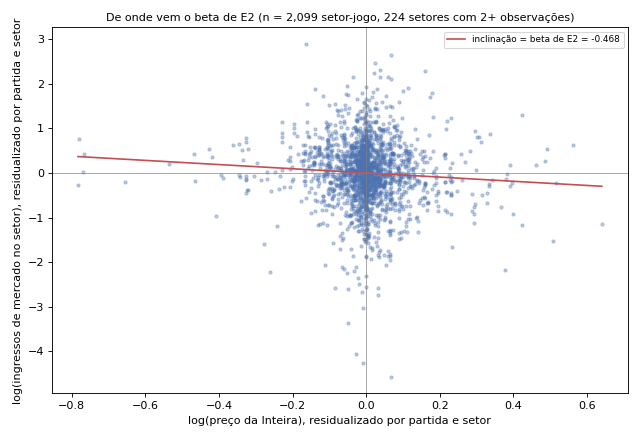

Pontos com log(preço) residualizado igual a zero: 246


In [8]:
unico = d.id_setor.map(d.id_setor.value_counts()) == 1
x_res, y_res = cent.lp[~unico], cent.lq[~unico]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(x_res, y_res, s=8, alpha=0.35, color="#4C72B0")
grade = np.linspace(x_res.min(), x_res.max(), 50)
ax.plot(grade, beta_proprio * grade, color="#C44E52", label=f"inclinação = beta de E2 = {beta_proprio:.3f}")
ax.axhline(0, color="gray", lw=0.6)
ax.axvline(0, color="gray", lw=0.6)
ax.set_xlabel("log(preço da Inteira), residualizado por partida e setor")
ax.set_ylabel("log(ingressos de mercado no setor), residualizado por partida e setor")
ax.set_title(f"De onde vem o beta de E2 (n = {(~unico).sum():,} setor-jogo, "
             f"{d[~unico].id_setor.nunique()} setores com 2+ observações)", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "residualizado_E2.png", dpi=150)
plt.show()
print(f"Pontos com log(preço) residualizado igual a zero: {(x_res.abs() < 1e-9).sum()}")

## Curva de especificação

Todas as variantes com erro agrupado em duas dimensões (jogo e setor),
exceto a linha de comparação agrupada só por jogo. Peso exógeno: média de
`q` do mesmo setor nos **outros** jogos (leave-one-out), o que exige pelo
menos duas observações do setor. Peso = `q` pondera pela própria variável
dependente. Os cortes por tamanho selecionam pela dependente. A variante
de arrecadação troca a dependente por log(arrecadação de mercado do setor),
que é outro estimando: o efeito do preço da Inteira sobre a receita do
setor.

In [9]:
agregado = merc.groupby(chave).agg(arrecadacao=("arrecadacao", "sum"))
inteira_q = ident.groupby(chave).vendidos.sum().rename("q_inteira")
d = d.drop(columns=[c for c in ("arrecadacao", "q_inteira") if c in d], errors="ignore")
d = d.join(agregado, on=chave).join(inteira_q, on=chave)
d["la"] = np.log(d.arrecadacao)
d["lq_inteira"] = np.log(d.q_inteira)
d["lpm"] = np.log(d.arrecadacao / d.q)
soma, cont = d.groupby("id_setor").q.transform("sum"), d.groupby("id_setor").q.transform("size")
d["peso_exogeno"] = (soma - d.q) / (cont - 1)
grandes = ["São Paulo", "Palmeiras", "Santos", "Corinthians"]


def estimar_duplo(df, y="lq", setor=True, peso=None, duplo=True):
    p = painel(df)
    r = PanelOLS(p[y], p[["lp"]], entity_effects=setor, time_effects=True,
                 weights=p[peso] if peso else None).fit(
        cov_type="clustered", cluster_time=True, cluster_entity=duplo)
    ic = r.conf_int().loc["lp"]
    return {"beta": r.params.lp, "erro_padrao": r.std_errors.lp, "ic95_inf": ic.lower,
            "ic95_sup": ic.upper, "n_obs": int(r.nobs), "n_jogos": df.id_jogo.nunique(),
            "n_setores": df.id_setor.nunique()}


variantes = [
    ("Principal", "E2, quantidade, sem peso (principal)", d, {}),
    ("Comparação", "E2, quantidade, sem peso, agrupado só por jogo", d, {"duplo": False}),
    ("Especificação", "E1, só efeito fixo de partida", d, {"setor": False}),
    ("Ponderação", "E2, peso exógeno (média de q do setor nos outros jogos)",
     d[cont > 1], {"peso": "peso_exogeno"}),
    ("Ponderação", "E2, peso = q (endógeno)", d, {"peso": "q"}),
    ("Quantidade", "E2, quantidade = só Inteira", d, {"y": "lq_inteira"}),
    ("Amostra", "E2, unidades com 100+ ingressos", d[d.q >= 100], {}),
    ("Amostra", "E2, unidades com 200+ ingressos", d[d.q >= 200], {}),
    ("Amostra", "E2, setores com >= 3 observações", d[contagem >= 3], {}),
    ("Amostra", "E2, setores com >= 5 observações", d[contagem >= 5], {}),
    ("Amostra", "E2, sem ocupação aparente >= 0,90", d[d.ocupacao_aparente < 0.90], {}),
    ("Mandante", "E2, sem os quatro grandes", d[~d.mandante.isin(grandes)], {}),
    ("Mandante", "E2, só os quatro grandes", d[d.mandante.isin(grandes)], {}),
] + [("Temporada", f"E3, E2 em {ano}", d[d.ano == ano], {}) for ano in sorted(d.ano.unique())] + [
    ("Receita", "E2, dependente = log(arrecadação do setor)", d, {"y": "la"}),
]
curva = pd.DataFrame([{"grupo": g, "variante": n, **estimar_duplo(df, **kw)}
                      for g, n, df, kw in variantes])
curva["agrupamento"] = np.where(curva.variante.str.contains("só por jogo"), "jogo", "jogo e setor")
curva["exclui_zero"] = (curva.ic95_sup < 0) | (curva.ic95_inf > 0)
curva.round(6).to_csv(RAIZ / "referencias" / "curva_especificacao.csv", index=False)
pd.set_option("display.width", 220)
print(curva[["grupo", "variante", "beta", "ic95_inf", "ic95_sup", "n_obs", "n_jogos",
             "n_setores", "agrupamento", "exclui_zero"]].round(3).to_string(index=False))

        grupo                                                variante   beta  ic95_inf  ic95_sup  n_obs  n_jogos  n_setores  agrupamento  exclui_zero
    Principal                    E2, quantidade, sem peso (principal) -0.468    -0.975     0.039   2212      387        337 jogo e setor        False
   Comparação          E2, quantidade, sem peso, agrupado só por jogo -0.468    -0.883    -0.053   2212      387        337         jogo         True
Especificação                           E1, só efeito fixo de partida -0.769    -1.259    -0.279   2212      387        337 jogo e setor         True
   Ponderação E2, peso exógeno (média de q do setor nos outros jogos) -0.383    -0.858     0.092   2099      377        224 jogo e setor        False
   Ponderação                                 E2, peso = q (endógeno)  0.114    -0.365     0.594   2212      387        337 jogo e setor        False
   Quantidade                             E2, quantidade = só Inteira -1.011    -1.683    -0.339   2

Repasse da Inteira para o preço médio realizado do setor (arrecadação /
q): o coeficiente de log(preço médio realizado) sobre log(preço da Inteira)
em E2. Como log(arrecadação) = log(q) + log(preço médio), os coeficientes
somam: beta de quantidade + repasse = beta de arrecadação.

In [10]:
repasse = estimar_duplo(d, y="lpm")
b_q = curva.loc[curva.variante.str.startswith("E2, quantidade, sem peso (principal)"), "beta"].item()
b_a = curva.loc[curva.grupo == "Receita", "beta"].item()
print(f"Repasse: {repasse['beta']:.3f} [{repasse['ic95_inf']:.3f}; {repasse['ic95_sup']:.3f}]")
print(f"Identidade: {b_q:.3f} + {repasse['beta']:.3f} = {b_q + repasse['beta']:.3f}; arrecadação: {b_a:.3f}")

Repasse: 0.916 [0.851; 0.981]
Identidade: -0.468 + 0.916 = 0.448; arrecadação: 0.448


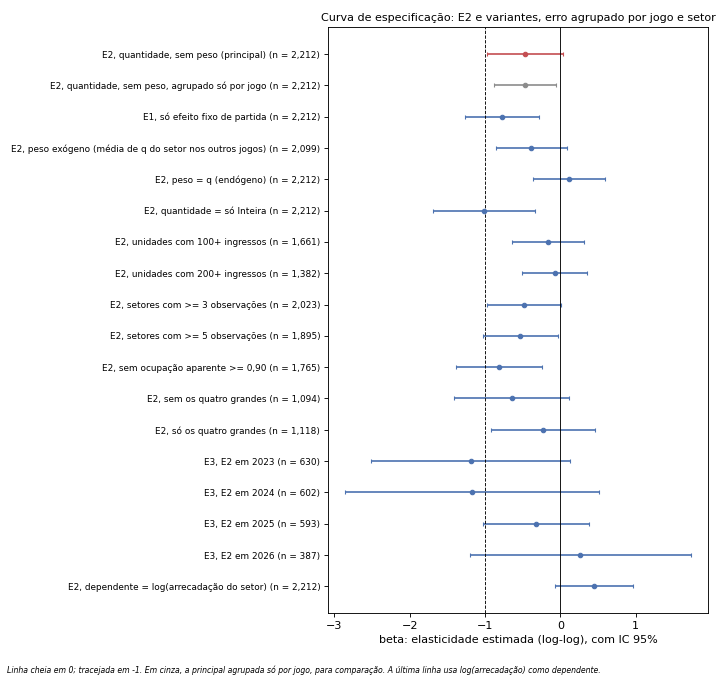

In [11]:
fig, ax = plt.subplots(figsize=(9, 8.5))
y = np.arange(len(curva))[::-1]
cores = {"Principal": "#C44E52", "Comparação": "#8C8C8C"}
for yi, (_, linha) in zip(y, curva.iterrows()):
    cor = cores.get(linha.grupo, "#4C72B0")
    ax.errorbar(linha.beta, yi, xerr=[[linha.beta - linha.ic95_inf], [linha.ic95_sup - linha.beta]],
                fmt="o", color=cor, ms=4, capsize=2)
ax.axvline(0, color="black", lw=0.8)
ax.axvline(-1, color="black", lw=0.8, ls="--")
ax.set_yticks(y)
ax.set_yticklabels([f"{v} (n = {n:,})" for v, n in zip(curva.variante, curva.n_obs)], fontsize=8)
ax.set_xlabel("beta: elasticidade estimada (log-log), com IC 95%")
ax.set_title("Curva de especificação: E2 e variantes, erro agrupado por jogo e setor", fontsize=10)
fig.text(0.01, 0.01, "Linha cheia em 0; tracejada em -1. Em cinza, a principal agrupada só por jogo, para comparação. "
         "A última linha usa log(arrecadação) como dependente.", fontsize=7, style="italic")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "curva_especificacao.png", dpi=150)
plt.show()